# Taller Practico: Redes Convolucionales (CNN) desde Cero
## Caso Didactico: Reconocimiento de Formas Geometricas Simples

En este taller aprenderas como una computadora "mira" imagenes y extrae sus patrones visuales usando Redes Neuronales Convolucionales (CNN).

### El problema:
Reconocer si una imagen en escala de grises contiene:
* Clase 0: **Circulo**
* Clase 1: **Cuadrado**
* Clase 2: **Cruz**

Trabajaremos con imagenes sinteticas pequenas de 28x28 pixeles, faciles de procesar en cualquier computadora.


### Explicacion sencilla de las piezas de una CNN

1. **`Conv2D` (Capa de Convolucion): Los ojos que buscan detalles.**
   * Pasa pequenas lupas o filtros (kernels de 3x3 pixeles) barriendo toda la imagen.
   * Su trabajo es detectar bordes, esquinas, lineas verticales u horizontales.
   * Si pones `filters=16`, la red aprende 16 lupas distintas para buscar 16 tipos de trazos diferentes.

2. **`MaxPooling2D` (Capa de Reduccion): El resumen visual.**
   * Toma cuadrantes pequenos (de 2x2 pixeles) y se queda solo con el pixel mas brillante o importante.
   * Efecto: Reduce el tamano de la imagen a la mitad (de 28x28 pasa a 14x14).
   * Beneficio: Acelera el entrenamiento y hace que la red reconozca la figura sin importar si esta un poco mas arriba o a la izquierda.

3. **`Flatten` (Aplanado): El traductor.**
   * Las imagenes son matrices 2D (alto x ancho). Las capas clasicas solo entienden una lista larga de numeros (1D).
   * Flatten estira la imagen como si fuera una cuerda de numeros continua sin perder informacion.

4. **`Dense` (Capa Clasificadora): El cerebro que decide.**
   * Recibe la lista de caracteristicas aplanadas y toma la decision final combinando todos los trazos encontrados.


### Paso 1: Importar librerias


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)


### Paso 2: Generar imagenes de figuras geometricas (Circulos, Cuadrados, Cruces)
Creamos 600 imagenes simples de 28x28 pixeles con su respectiva etiqueta.


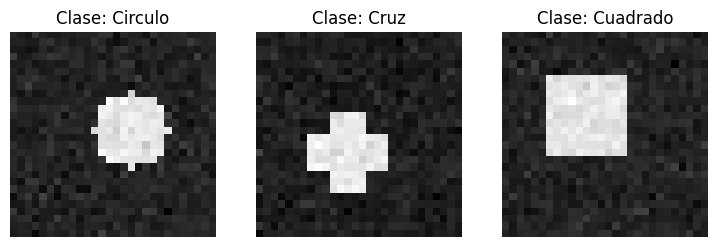

In [ ]:
def generar_figuras(n_por_clase=200):
    imagenes = []
    etiquetas = []

    # 0 = Circulo, 1 = Cuadrado, 2 = Cruz
    for _ in range(n_por_clase):
        # Circulo
        img = np.zeros((28, 28), dtype=np.float32)
        cx, cy = np.random.randint(10, 18, 2)
        r = np.random.randint(5, 8)
        y, x = np.ogrid[:28, :28]
        mask = (x - cx)**2 + (y - cy)**2 <= r**2
        img[mask] = 1.0
        img += np.random.normal(0, 0.05, (28, 28)) # Ruido suave
        imagenes.append(img)
        etiquetas.append(0)

        # Cuadrado
        img = np.zeros((28, 28), dtype=np.float32)
        x1, y1 = np.random.randint(6, 12, 2)
        lado = np.random.randint(9, 13)
        img[y1:y1+lado, x1:x1+lado] = 1.0
        img += np.random.normal(0, 0.05, (28, 28))
        imagenes.append(img)
        etiquetas.append(1)

        # Cruz
        img = np.zeros((28, 28), dtype=np.float32)
        cx, cy = np.random.randint(11, 17, 2)
        ancho = 2
        img[cy-5:cy+6, cx-ancho:cx+ancho+1] = 1.0
        img[cy-ancho:cy+ancho+1, cx-5:cx+6] = 1.0
        img += np.random.normal(0, 0.05, (28, 28))
        imagenes.append(img)
        etiquetas.append(2)

    return np.array(imagenes), np.array(etiquetas)

X, y = generar_figuras(n_por_clase=200)

# Keras exige que las imagenes tengan dimension de canal: (muestras, alto, ancho, canales)
# Como es escala de grises, el canal es 1.
X = np.expand_dims(X, axis=-1)

nombres_clases = ['Circulo', 'Cuadrado', 'Cruz']

# Visualizar 3 ejemplos
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for i in range(3):
    ax[i].imshow(X[i*200].squeeze(), cmap='gray')
    ax[i].set_title(f"Clase: {nombres_clases[y[i*200]]}")
    ax[i].axis('off')
plt.show()


### Paso 3: Separar en entrenamiento y prueba


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Dimensiones de entrenamiento: {X_train.shape}")
print(f"Dimensiones de prueba: {X_test.shape}")


Dimensiones de entrenamiento: (450, 28, 28, 1)
Dimensiones de prueba: (150, 28, 28, 1)


### Paso 4: Construir la Red Neuronal Convolucional (CNN)

### Que puedes modificar para experimentar:
* `filters` en Conv2D: Puedes probar con 8, 16 o 32 filtros.
* Anadir otro bloque convolucional: `Conv2D` seguido de otro `MaxPooling2D`.
* Neuronas en la capa `Dense` oculta (ej. 16, 32 o 64).

### Reglas obligatorias que no debes cambiar:
* La capa de salida debe tener `3` neuronas (una para cada figura).
* La activacion de salida debe ser `'softmax'` (calcula probabilidades de 0% a 100%).
* La perdida (loss) debe ser `'sparse_categorical_crossentropy'`.


In [ ]:
modelo_cnn = Sequential([
    # Bloque Convolucional 1: Detecta bordes y formas basicas
    Conv2D(filters=16, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)), # Reduce de 26x26 a 13x13

    # Bloque Convolucional 2: Detecta combinaciones de trazos
    Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)), # Reduce a 5x5

    # Aplanado: Convierte el mapa 2D a una lista continua de numeros
    Flatten(),

    # Capas densas de clasificacion
    Dense(units=32, activation='relu'),

    # Capa de salida: 3 figuras con softmax
    Dense(units=3, activation='softmax')
])

modelo_cnn.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelo_cnn.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,531 (119.26 KB)

 Trainable params: 30,531 (119.26 KB)

 Non-trainable params: 0 (0.00 B)

### Paso 5: Entrenar el modelo


In [ ]:
# Entrenamos durante 15 a 20 epocas
historia = modelo_cnn.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)


Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.5111 - loss: 1.0446 - val_accuracy: 0.5667 - val_loss: 0.9825
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6778 - loss: 0.8689 - val_accuracy: 0.7111 - val_loss: 0.7792
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8278 - loss: 0.6108 - val_accuracy: 0.7000 - val_loss: 0.6425
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8944 - loss: 0.4037 - val_accuracy: 0.8556 - val_loss: 0.4097
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9417 - loss: 0.2567 - val_accuracy: 0.8778 - val_loss: 0.2927
Epoch 6/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9583 - loss: 0.1740 - val_accuracy: 0.9444 - val_loss: 0.2081
Epoch 7/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9750 - loss: 0.1177 - val_accuracy: 0.9778 - val_loss: 0.1315
Epoch 8/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9917 - loss: 0.0757 - val_accuracy: 1.0000 - v

### Paso 6: Evaluacion y Pruebas Visuales
Hacemos que la red reconozca imagenes del conjunto de prueba y mostramos la prediccion con su nivel de certeza.


Precision global en imagenes no vistas: 100.0 %

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step


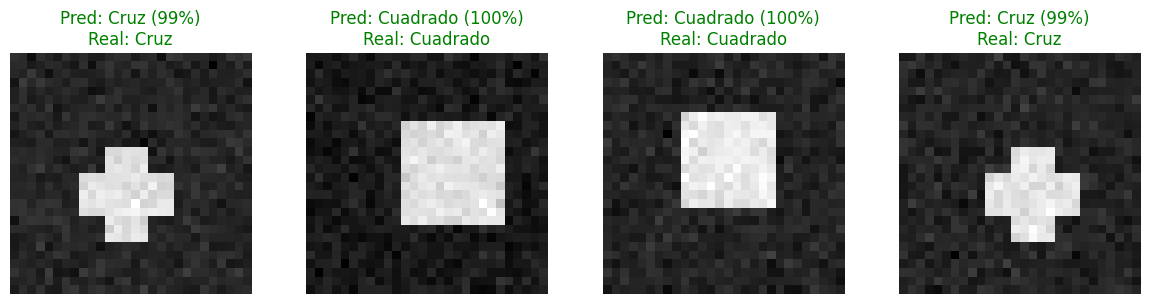

In [ ]:
test_loss, test_acc = modelo_cnn.evaluate(X_test, y_test, verbose=0)
print(f"Precision global en imagenes no vistas: {test_acc * 100:.1f} %\n")

# Probar predicciones con las primeras 4 imagenes de prueba
predicciones = modelo_cnn.predict(X_test[:4])
clases_predichas = np.argmax(predicciones, axis=1)

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    ax[i].imshow(X_test[i].squeeze(), cmap='gray')
    certeza = np.max(predicciones[i]) * 100
    color = 'green' if clases_predichas[i] == y_test[i] else 'red'
    ax[i].set_title(f"Pred: {nombres_clases[clases_predichas[i]]} ({certeza:.0f}%)\nReal: {nombres_clases[y_test[i]]}", color=color)
    ax[i].axis('off')
plt.tight_layout()
plt.show()
